# 🤖 Automações em Python: Cotação do Dólar ao Vivo

**Live da Pós | Disciplina de Python | 26/11/2026**

Nesta automação, o Python vai **buscar na internet** a cotação do dólar (e de outras moedas), **organizar** o histórico dos últimos dias em uma tabela e **desenhar um gráfico**, tudo sozinho, com um clique.

### O que é uma API?
Pense em um **garçom** 🍽️: você (o Python) faz o pedido, o garçom (a API) leva até a cozinha (o servidor) e volta com o prato (os dados).
Aqui vamos usar a **AwesomeAPI**, que é gratuita e não precisa de cadastro:

- Cotação atual: `https://economia.awesomeapi.com.br/json/last/USD-BRL`
- Histórico: `https://economia.awesomeapi.com.br/json/daily/USD-BRL/15`

> 💡 Dica: abra o primeiro link no navegador para ver como os dados chegam!

### 🏷️ Legenda dos comentários

Em todo o código, os comentários têm **etiquetas** para você identificar cada conceito de Python:

| Etiqueta | Conceito | Como reconhecer no código |
|---|---|---|
| `[MÓDULO]` | Caixa de ferramentas pronta (biblioteca) | `import nome` |
| `[VARIÁVEL]` | "Caixinha" com nome que guarda um valor | `nome = valor` |
| `[LISTA]` | Coleção ordenada de itens | `[item1, item2]` |
| `[DICIONÁRIO]` | Coleção de pares **chave → valor** | `{"chave": valor}` |
| `[FUNÇÃO]` | Bloco de código com nome, que pode ser reaproveitado | criada com `def nome():`, usada com `nome()` |
| `[MÉTODO]` | Função que **pertence a um objeto** | `objeto.metodo()` **com** parênteses |
| `[ATRIBUTO]` | Informação guardada **dentro** de um objeto | `objeto.atributo` **sem** parênteses |
| `[CLASSE]` | Molde para criar objetos | `class Nome:` |
| `[OBJETO]` | Algo criado a partir de uma classe | `variavel = Classe(...)` |
| `[LOOP]` | Repetição | `for item in lista:` |
| `[CONDICIONAL]` | Decisão | `if ... else ...` |

> ⚠️ **Método × Atributo:** o método **faz algo** e por isso tem parênteses `()`. O atributo **é uma informação** e não tem parênteses.

## Passo 1: Importar os módulos

Um **módulo** é uma "caixa de ferramentas" que alguém já programou. Em vez de escrever tudo do zero, a gente **importa** e usa.

In [1]:
# ============================================================
# PASSO 1 - IMPORTAR OS MÓDULOS
# ============================================================

# [MÓDULO] requests -> faz pedidos (requisições) para sites e APIs na internet
# (foi o pacote que instalamos com: pip install requests)
import requests

# [MÓDULO] pandas -> trabalha com tabelas (chamadas de DataFrame)
# "as pd" cria um APELIDO: em vez de escrever "pandas" toda vez, escrevemos "pd"
import pandas as pd

# [MÓDULO] matplotlib.pyplot -> desenha gráficos. Apelido: "plt"
import matplotlib.pyplot as plt

# [MÓDULO] datetime -> trabalha com datas e horas (já vem com o Python, não precisa instalar)
# "from ... import ..." traz só uma PARTE do módulo: neste caso, a classe datetime
from datetime import datetime

# [FUNÇÃO] print() é uma função embutida (built-in) do Python: mostra algo na tela
print("Módulos importados com sucesso! ✅")

Módulos importados com sucesso! ✅


## Passo 2: Configurações

Aqui ficam os valores que podemos mudar facilmente, como a moeda e quantos dias de histórico queremos.
Quer ver o euro? É só trocar `"USD-BRL"` por `"EUR-BRL"` aqui.

In [2]:
# ============================================================
# PASSO 2 - CONFIGURAÇÕES
# ============================================================
# Por convenção, variáveis de configuração são escritas em MAIÚSCULAS.

# [VARIÁVEL] do tipo texto (str): dólar americano convertido para real
MOEDA = "USD-BRL"

# [VARIÁVEL] do tipo número inteiro (int): quantos dias (úteis) de histórico
DIAS = 15

# [VARIÁVEL] endereço da API.
# O "f" antes das aspas cria uma f-string: o que está entre { } é
# substituído pelo valor da variável. Aqui {MOEDA} vira USD-BRL.
URL_ATUAL = f"https://economia.awesomeapi.com.br/json/last/{MOEDA}"

print("Vamos consultar:", URL_ATUAL)

Vamos consultar: https://economia.awesomeapi.com.br/json/last/USD-BRL


## Passo 3: Fazer o primeiro pedido para a API

Primeiro vamos fazer tudo **passo a passo, sem função**, para entender o que acontece.
O Python "visita" o endereço da API e recebe uma **resposta**.

In [3]:
# ============================================================
# PASSO 3 - O PRIMEIRO PEDIDO (sem função ainda)
# ============================================================

# [FUNÇÃO] requests.get() é uma função do módulo requests.
# Ela "visita" o endereço e traz a resposta de volta.
# timeout=10 -> se a internet travar, desiste depois de 10 segundos.
#
# 🏷️ ARGUMENTOS NOMEADOS: em vez de passar só os valores, escrevemos o NOME
# de cada um (url=... e timeout=...). Assim fica claro O QUE é cada valor
# e a ordem não importa.
# Vamos usar esse estilo no notebook inteiro, sempre que possível.
# Algumas funções do próprio Python NÃO aceitam nomes e só funcionam pela ordem,
# como print(), type(), len() e float(), e métodos como .replace() e .append().
# Nesses casos, deixamos sem nome.
# No gráfico, o x e o y do ax.plot() também vão pela ordem: é a convenção do matplotlib.
resposta = requests.get(url=URL_ATUAL, timeout=10)

# [OBJETO] "resposta" é um objeto. [FUNÇÃO] type() mostra de que tipo ele é.
# Vai aparecer: <class 'requests.models.Response'>
# Ou seja: "resposta" foi criado a partir da [CLASSE] Response, que foi escrita
# pela equipe do pacote requests (ela fica no arquivo "models" do pacote).
#
# É a mesma ideia da nossa classe Cotacao (que vamos criar no Passo 5),
# só que quem escreveu a classe Response foram os autores do requests:
#
#                 NOSSA CLASSE                   CLASSE DO REQUESTS
#   Classe        Cotacao                        Response
#   Objeto        dolar = buscar_cotacao(...)    resposta = requests.get(...)
#   Atributos     dolar.valor, dolar.nome        resposta.status_code, resposta.text,
#                                                resposta.url, resposta.headers
#   Métodos       dolar.mostrar()                resposta.json(), resposta.raise_for_status()
#
# 💡 Como descobrir tudo o que um objeto tem:
#   dir(resposta)   -> [FUNÇÃO] lista todos os atributos e métodos do objeto
#   help(resposta)  -> [FUNÇÃO] mostra a documentação da classe
#   ou digite "resposta." e aperte Tab: aparece a lista de opções
print("Tipo da resposta:", type(resposta))

# [ATRIBUTO] status_code -> código da resposta (200 = deu tudo certo).
# Repare: SEM parênteses, porque é uma informação, não uma ação.
print("Código da resposta:", resposta.status_code)

# [MÉTODO] .json() -> converte o texto que veio da internet em um dicionário Python.
# Repare: COM parênteses, porque é uma ação.
dados = resposta.json()

# ⚠️ Repare: "dados" NÃO é mais um objeto Response!
# Depois do .json(), ele virou um [DICIONÁRIO] (dict) comum do Python.
# Por isso, daqui para frente, os métodos disponíveis são os de dicionário,
# como dados.keys(), dados.items() e dados.get().
#   type(resposta) -> <class 'requests.models.Response'>
#   type(dados)    -> <class 'dict'>
# Lição importante: o TIPO do objeto define o que você pode fazer com ele.
print("Tipo dos dados:", type(dados))
print()  # linha em branco
print(dados)

Tipo da resposta: <class 'requests.models.Response'>
Código da resposta: 200
Tipo dos dados: <class 'dict'>

{'USDBRL': {'code': 'USD', 'codein': 'BRL', 'name': 'Dólar Americano/Real Brasileiro', 'high': '5.6525', 'low': '5.4833', 'varBid': '-0.1247', 'pctChange': '-2.206571', 'bid': '5.5266', 'ask': '5.5271', 'timestamp': '1795807253', 'create_date': '2026-11-27 16:20:53'}}


## Passo 4: Pegar só o que interessa

A API devolve um **dicionário** com várias informações. Os campos que vamos usar:

| Chave | Significado |
|---|---|
| `bid` | Valor de compra |
| `pctChange` | Variação no dia (%) |
| `create_date` | Data e hora da cotação |
| `name` | Nome da moeda |

In [4]:
# ============================================================
# PASSO 4 - EXTRAIR OS VALORES DO DICIONÁRIO
# ============================================================

# [DICIONÁRIO] acessamos um valor pela CHAVE, usando colchetes [ ].
# Os dados vêm dentro de uma chave com o nome da moeda SEM o hífen:
# "USD-BRL" -> "USDBRL", "EUR-BRL" -> "EURBRL"...
# [MÉTODO] .replace() é um método de TEXTO: troca "-" por "" (nada).
# Assim, se você trocar a MOEDA no Passo 2, este passo continua funcionando.
chave = MOEDA.replace("-", "")
cotacao = dados[chave]

# Os números vêm como TEXTO (str), por exemplo "5.821".
# [FUNÇÃO] float() é uma função embutida que converte texto em número decimal.
valor = float(cotacao["bid"])
variacao = float(cotacao["pctChange"])
data = cotacao["create_date"]

# Formatação dentro da f-string:
#   :.4f   -> mostra o número com 4 casas decimais
#   :+.2f  -> 2 casas decimais e SEMPRE mostra o sinal
#            (positivo sai com "+", negativo sai com "-")
print(f"💵 Dólar agora: R$ {valor:.4f}")
print(f"📊 Variação no dia: {variacao:+.2f}%")
print(f"🕒 Atualizado em: {data}")

💵 Dólar agora: R$ 5.5266
📊 Variação no dia: -2.21%
🕒 Atualizado em: 2026-11-27 16:20:53


## Passo 5: Criar uma classe

Funcionou! Mas e se quisermos ver o **euro**, a **libra** e o **bitcoin**? Copiar e colar o código 4 vezes não é uma boa ideia. 😅

Vamos criar uma **classe**, que é um **molde**. Ela diz:
- **que informações** toda cotação tem (os **atributos**: nome, valor, variação e data);
- **o que** toda cotação sabe fazer (os **métodos**: se mostrar na tela).

> Analogia: a classe é a **forma de bolo**, e cada objeto é um **bolo** feito com ela.

In [5]:
# ============================================================
# PASSO 5 - A CLASSE COTACAO (o "molde")
# ============================================================

# [CLASSE] criada com a palavra "class". Por convenção, o nome começa com letra maiúscula.
class Cotacao:

    # [MÉTODO] __init__ é um método ESPECIAL: roda sozinho quando criamos um objeto novo.
    # "self" representa o próprio objeto que está sendo criado.
    def __init__(self, nome, valor, variacao, data):
        # [ATRIBUTO] cada "self.alguma_coisa" guarda uma informação DENTRO do objeto
        self.nome = nome
        self.valor = valor
        self.variacao = variacao
        self.data = data

    # [MÉTODO] mostrar() é uma função que pertence à classe:
    # todo objeto Cotacao sabe se mostrar na tela.
    def mostrar(self):
        # [CONDICIONAL] if/else escolhe a seta: subiu ou caiu?
        if self.variacao >= 0:
            seta = "🟢 ▲"
        else:
            seta = "🔴 ▼"

        print(f"{self.nome:<35} R$ {self.valor:>12.4f}   {seta} {self.variacao:+.2f}%")

In [6]:
# Testando o molde com valores inventados:
# [OBJETO] "teste" é um objeto criado a partir da classe Cotacao
teste = Cotacao(nome="Moeda de Teste", valor=1.2345, variacao=-0.5, data="hoje")

In [7]:
print(type(teste))

<class '__main__.Cotacao'>


In [8]:
print(teste.variacao)   # [ATRIBUTO] sem parênteses -> é uma informação

-0.5


In [9]:
teste.mostrar()      # [MÉTODO]   com parênteses -> é uma ação

Moeda de Teste                      R$       1.2345   🔴 ▼ -0.50%


## Passo 6: Criar uma função que busca qualquer moeda

Agora juntamos os **Passos 3 e 4** dentro de uma **função**. Assim, para buscar qualquer moeda, basta uma linha:
`buscar_cotacao(moeda="EUR-BRL")`.

- **Parâmetro**: a informação que a função recebe (aqui, a `moeda`).
- **return**: o resultado que a função devolve (aqui, um objeto `Cotacao`).

In [10]:
# ============================================================
# PASSO 6 - A FUNÇÃO buscar_cotacao
# ============================================================

# [FUNÇÃO] criada com "def". "moeda" é o PARÂMETRO (o que a função recebe).
def buscar_cotacao(moeda):

    # [VARIÁVEL] monta o endereço com a moeda recebida (f-string)
    url = f"https://economia.awesomeapi.com.br/json/last/{moeda}"

    # [FUNÇÃO] requests.get() faz o pedido (igual ao Passo 3)
    resposta = requests.get(url=url, timeout=10)

    # [MÉTODO] raise_for_status() -> se a API responder com erro, para e avisa
    resposta.raise_for_status()

    # [MÉTODO] .json() transforma a resposta em dicionário
    dados = resposta.json()

    # [MÉTODO] .replace() troca "-" por "" (igual ao Passo 4).
    # Assim, "USD-BRL" vira "USDBRL", que é a chave do dicionário.
    chave = moeda.replace("-", "")
    info = dados[chave]   # [DICIONÁRIO] acesso pela chave

    # [OBJETO] criamos um objeto usando a nossa classe Cotacao (o molde)
    cotacao = Cotacao(
        nome=info["name"],
        valor=float(info["bid"]),
        variacao=float(info["pctChange"]),
        data=info["create_date"],
    )

    # "return" devolve o objeto para quem chamou a função
    return cotacao

In [11]:
# Usando a função:
dolar = buscar_cotacao(moeda="USD-BRL")   # [FUNÇÃO] chamada da nossa função
print(type(dolar))

<class '__main__.Cotacao'>


In [12]:
print("Valor:", dolar.valor)        # [ATRIBUTO]
print("Data:", dolar.data)          # [ATRIBUTO]

Valor: 5.5266
Data: 2026-11-27 16:20:53


In [13]:
dolar.mostrar()                     # [MÉTODO]

Dólar Americano/Real Brasileiro     R$       5.5266   🔴 ▼ -2.21%


## Passo 7: Repetir para várias moedas com um loop

Com a função pronta, um **loop `for`** busca todas as moedas de uma lista, **uma de cada vez**.

In [14]:
# ============================================================
# PASSO 7 - PAINEL DE COTAÇÕES (LOOP)
# ============================================================

# [LISTA] coleção de moedas, escrita entre colchetes [ ]
moedas = ["USD-BRL", "EUR-BRL", "GBP-BRL", "BTC-BRL"]

# [MÉTODO] datetime.now() pega a data e a hora deste momento
# [MÉTODO] .strftime() formata a data como texto (%d=dia, %m=mês, %Y=ano, %H:%M=hora:minuto)
agora = datetime.now().strftime(format="%d/%m/%Y %H:%M")

print("=" * 75)   # o texto "=" repetido 75 vezes
print(f"   PAINEL DE COTAÇÕES | {agora}")
print("=" * 75)

# [LOOP] for: "para cada moeda dentro da lista moedas, faça..."
# Tudo que está INDENTADO (com recuo) abaixo do for se repete.
for moeda in moedas:
    cotacao = buscar_cotacao(moeda=moeda)   # [FUNÇÃO] chama a nossa função
    cotacao.mostrar()                 # [MÉTODO] chama o método do objeto

print("=" * 75)

   PAINEL DE COTAÇÕES | 27/11/2026 16:22
Dólar Americano/Real Brasileiro     R$       5.5266   🔴 ▼ -2.21%
Euro/Real Brasileiro                R$       6.0417   🔴 ▼ -2.54%
Libra Esterlina/Real Brasileiro     R$       7.2346   🔴 ▼ -2.31%
Bitcoin/Real Brasileiro             R$  331395.0000   🔴 ▼ -5.06%


## Passo 8: Espiando o histórico (sem função)

Antes de criar a função do Passo 9, vamos **ver com os próprios olhos** o que o endereço de histórico devolve.

Repare na diferença entre os dois endereços:

| Endereço | O que devolve |
|---|---|
| `.../json/last/USD-BRL` | **uma** cotação (a mais recente), dentro de um **dicionário** |
| `.../json/daily/USD-BRL/15` | **várias** cotações (uma por dia, quase sempre dias úteis), dentro de uma **lista** |

> 📅 A data vem como **timestamp**, que é o número de **segundos desde 01/01/1970** (ex.: `1795730936`). No Passo 9, vamos transformar esse número em uma data de verdade.

In [15]:
# ============================================================
# PASSO 8 - ESPIANDO O HISTÓRICO (sem função ainda)
# ============================================================

# [VARIÁVEL] endereço do HISTÓRICO. Repare no "/daily/" e na quantidade de dias no final.
# {MOEDA} e {DIAS} vêm das configurações do Passo 2 (f-string)
URL_HISTORICO = f"https://economia.awesomeapi.com.br/json/daily/{MOEDA}/{DIAS}"
print("Vamos consultar:", URL_HISTORICO)

Vamos consultar: https://economia.awesomeapi.com.br/json/daily/USD-BRL/15


In [16]:
# [FUNÇÃO] requests.get() faz o pedido, igual ao Passo 3
resposta = requests.get(url=URL_HISTORICO, timeout=10)

# [MÉTODO] .json() converte a resposta em estruturas do Python
historico_bruto = resposta.json()

In [17]:
# A GRANDE DIFERENÇA: no Passo 3 veio um [DICIONÁRIO]; agora vem uma [LISTA]
print("Tipo dos dados:", type(historico_bruto))

Tipo dos dados: <class 'list'>


In [18]:
# [FUNÇÃO] len() conta quantos itens a lista tem: uma cotação por dia (quase sempre dias úteis)
print("Quantidade de cotações:", len(historico_bruto))

Quantidade de cotações: 15


In [19]:
# explorando essa lista
historico_bruto

[{'code': 'USD',
  'codein': 'BRL',
  'name': 'Dólar Americano/Real Brasileiro',
  'high': '5.6525',
  'low': '5.4833',
  'varBid': '-0.1227',
  'pctChange': '-2.17118',
  'bid': '5.5286',
  'ask': '5.5291',
  'timestamp': '1795806406',
  'create_date': '2026-11-27 16:06:46'},
 {'high': '5.8254',
  'low': '5.6413',
  'varBid': '-0.1697',
  'pctChange': '-2.91531',
  'bid': '5.6513',
  'ask': '5.6518',
  'timestamp': '1795730936'},
 {'high': '5.9566',
  'low': '5.8056',
  'varBid': '-0.0845',
  'pctChange': '-1.43087',
  'bid': '5.821',
  'ask': '5.8215',
  'timestamp': '1795644621'},
 {'high': '5.9517',
  'low': '5.8034',
  'varBid': '-0.024',
  'pctChange': '-0.404758',
  'bid': '5.9055',
  'ask': '5.9056',
  'timestamp': '1795560250'},
 {'high': '6.0032',
  'low': '5.9223',
  'varBid': '-0.0193',
  'pctChange': '-0.324437',
  'bid': '5.9295',
  'ask': '5.9296',
  'timestamp': '1795476759'},
 {'high': '5.9488',
  'low': '5.9292',
  'varBid': '0.0131',
  'pctChange': '0.2207',
  'bid':

In [20]:
# [LISTA] posição 0 = o primeiro item.
# Ele TAMBÉM é uma cotação: a do dia MAIS RECENTE.
# São 15 cotações no total, da posição 0 até a 14:
#
#   Posição   Qual dia
#   0         o mais recente (hoje)
#   1         o dia útil anterior
#   2         dois dias úteis antes
#   ...       ...
#   14        o mais antigo
#
# Por que a posição 0 tem MAIS chaves ("code", "codein", "name", "create_date")?
# A API aproveita o primeiro item para mandar também as informações de
# "cabeçalho" (QUE moeda é essa). Como elas valem para a lista inteira,
# a API não repete em todos os itens: coloca só no primeiro, para economizar.
#
# 💡 A posição 0 é a cotação mais recente: a mesma do endereço "/last/"
#    que usamos nos Passos 3 e 4, ou alguns minutos mais antiga, porque o
#    "/daily/" atualiza com um pequeno atraso (compare o valor e a data!).
print("Primeiro item:", historico_bruto[0])
print()

# [LISTA] posição 1 = o segundo item (a cotação do dia anterior).
# Repare: ele tem MENOS chaves. Da posição 1 em diante vem SÓ a cotação,
# sem repetir as informações da moeda ("code", "name"...).
#
# Por isso, no Passo 9, a função usa TODOS os itens (inclusive o 0),
# mas lê só as chaves que existem em todos: "timestamp" e "bid".
print("Segundo item:", historico_bruto[1])
print()

Primeiro item: {'code': 'USD', 'codein': 'BRL', 'name': 'Dólar Americano/Real Brasileiro', 'high': '5.6525', 'low': '5.4833', 'varBid': '-0.1227', 'pctChange': '-2.17118', 'bid': '5.5286', 'ask': '5.5291', 'timestamp': '1795806406', 'create_date': '2026-11-27 16:06:46'}

Segundo item: {'high': '5.8254', 'low': '5.6413', 'varBid': '-0.1697', 'pctChange': '-2.91531', 'bid': '5.6513', 'ask': '5.6518', 'timestamp': '1795730936'}



In [21]:
# [LOOP] percorre a lista e mostra uma linha para cada cotação
print("timestamp      valor")
print("-" * 22)
for item in historico_bruto:
    # [DICIONÁRIO] cada item é um dicionário: acessamos pela chave
    print(item["timestamp"], "  ", item["bid"])

timestamp      valor
----------------------
1795806406    5.5286
1795730936    5.6513
1795644621    5.821
1795560250    5.9055
1795476759    5.9295
1795198734    5.9488
1795122463    5.9357
1795039210    5.8831
1794955012    5.778
1794868960    5.784
1794605388    5.6674
1794523285    5.6419
1794436919    5.583
1794348310    5.5829
1794264226    5.5086


## Passo 9: Transformar o histórico em uma tabela

No Passo 8, vimos que o endereço de histórico devolve uma **lista de dicionários**, com uma cotação em cada item. Mas, do jeito que chega, ela ainda não serve para análise:

- a data vem como **timestamp** (ex.: `1795644621`), que ninguém consegue ler;
- os valores vêm como **texto** (ex.: `"5.821"`), e não dá para fazer contas com texto;
- a ordem é do **mais recente para o mais antigo**, ao contrário do que um gráfico precisa.

Agora vamos guardar tudo isso dentro de uma **função**, a `buscar_historico()`. Ela:

1. faz o pedido à API (igual ao Passo 8);
2. percorre a lista com um **loop**, convertendo a data e o valor de cada item;
3. monta uma **tabela** (DataFrame) do pandas;
4. ordena do dia **mais antigo** para o **mais recente**.

> 📅 A API devolve praticamente só **dias úteis**, então 15 cotações cobrem cerca de 3 semanas.
> Curiosidade: às vezes aparece um **domingo**! É que o mercado de câmbio reabre no domingo à noite, e a API registra essa cotação.

In [22]:
# ============================================================
# PASSO 9 - A FUNÇÃO buscar_historico
# ============================================================

# [FUNÇÃO] agora com DOIS parâmetros: a moeda e a quantidade de dias
def buscar_historico(moeda, dias):

    url = f"https://economia.awesomeapi.com.br/json/daily/{moeda}/{dias}"
    resposta = requests.get(url=url, timeout=10)
    resposta.raise_for_status()

    # Desta vez, .json() devolve uma [LISTA] de [DICIONÁRIOS] (um para cada dia)
    dados = resposta.json()

    # [LISTA] começa vazia; vamos enchendo dentro do loop
    linhas = []

    # [LOOP] para cada dia que veio da API...
    for item in dados:
        # A data vem como "timestamp" (segundos desde 01/01/1970), em texto.
        # [FUNÇÃO] int() converte o texto em número inteiro.
        # [MÉTODO] datetime.fromtimestamp() converte esse número em data.
        # [MÉTODO] .date() fica só com a data (sem a hora).
        data = datetime.fromtimestamp(timestamp=int(item["timestamp"])).date()
        valor = float(item["bid"])

        # [MÉTODO] .append() adiciona um item no FIM da lista.
        # Cada item é um [DICIONÁRIO] que vai virar uma linha da tabela.
        linhas.append({"data": data, "valor": valor})

    # [CLASSE] pd.DataFrame é uma classe do pandas.
    # [OBJETO] "tabela" é um objeto DataFrame criado a partir da nossa lista.
    tabela = pd.DataFrame(data=linhas)

    # [MÉTODO] .sort_values() ordena pela coluna "data" (do mais antigo ao mais novo)
    tabela = tabela.sort_values(by="data")

    # [MÉTODO] .reset_index() renumera as linhas de 0 em diante, já na nova ordem
    tabela = tabela.reset_index(drop=True)

    return tabela

In [23]:
DIAS

15

In [24]:
# Usando a função com as configurações do Passo 2:
historico = buscar_historico(moeda=MOEDA, dias=DIAS)
print(type(historico))

<class 'pandas.DataFrame'>


In [25]:
# Em um notebook, deixar a variável na última linha mostra a tabela formatada
historico

,data,valor
0,2026-11-09,5.5086
1,2026-11-10,5.5829
2,2026-11-11,5.5830
3,2026-11-12,5.6419
4,2026-11-13,5.6674
5,2026-11-16,5.7840
6,2026-11-17,5.7780
7,2026-11-18,5.8831
8,2026-11-19,5.9357
9,2026-11-20,5.9488


In [26]:
# ============================================================
# PASSO 9.1 - UM RESUMO DO PERÍODO
# ============================================================

# historico["valor"] pega só a coluna "valor" da tabela.
# [MÉTODO] .min(), .max() e .mean() calculam o menor valor, o maior e a média.
menor = historico["valor"].min()
maior = historico["valor"].max()
media = historico["valor"].mean()

# [ATRIBUTO] .iloc permite pegar uma linha pela POSIÇÃO. [-1] = a última (o dia mais recente)
ultimo = historico["valor"].iloc[-1]

# [FUNÇÃO] len() conta quantas linhas (dias) a tabela tem
print(f"📅 Dias analisados: {len(historico)}")
print(f"⬇️  Menor valor: R$ {menor:.4f}")
print(f"⬆️  Maior valor: R$ {maior:.4f}")
print(f"➗ Média:       R$ {media:.4f}")
print(f"🕒 Mais recente: R$ {ultimo:.4f}")

📅 Dias analisados: 15
⬇️  Menor valor: R$ 5.5086
⬆️  Maior valor: R$ 5.9488
➗ Média:       R$ 5.7433
🕒 Mais recente: R$ 5.5286


## Passo 10: Desenhar o gráfico

Com o `matplotlib`, transformamos a tabela em um gráfico de linha. Cada comando `ax.alguma_coisa()` é um **método** que acrescenta um detalhe ao gráfico.

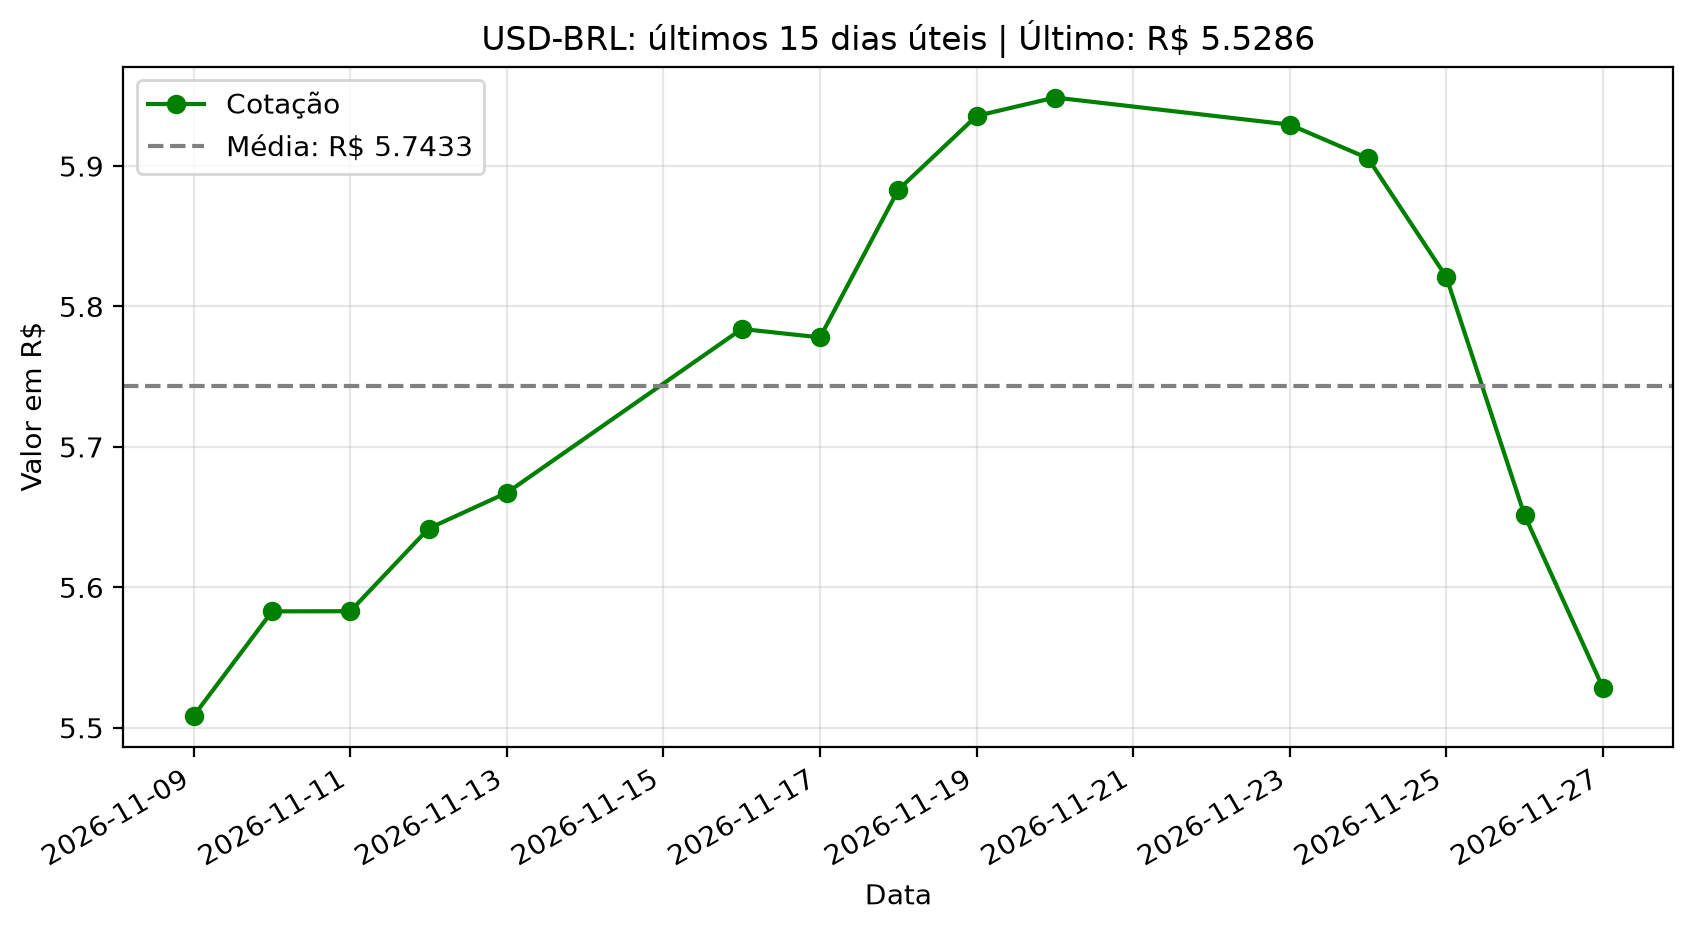

In [27]:
# ============================================================
# PASSO 10 - O GRÁFICO
# ============================================================

# [FUNÇÃO] plt.subplots() cria a figura (fig) e a área do gráfico (ax).
# figsize=(10, 5) -> largura 10 e altura 5
fig, ax = plt.subplots(figsize=(10, 5))

# [MÉTODO] ax.plot() desenha a linha: eixo X = datas, eixo Y = valores
# marker="o" coloca uma bolinha em cada dia
ax.plot(historico["data"], historico["valor"], marker="o", color="green", label="Cotação")

# [MÉTODO] ax.axhline() desenha uma linha horizontal na média
ax.axhline(y=media, linestyle="--", color="gray", label=f"Média: R$ {media:.4f}")

# [MÉTODO] títulos e nomes dos eixos
ax.set_title(label=f"{MOEDA}: últimos {DIAS} dias úteis | Último: R$ {ultimo:.4f}")
ax.set_xlabel(xlabel="Data")
ax.set_ylabel(ylabel="Valor em R$")

# [MÉTODO] grade de fundo (alpha = transparência) e legenda
ax.grid(visible=True, alpha=0.3)
ax.legend()

# [MÉTODO] inclina as datas do eixo X para não ficarem uma em cima da outra
fig.autofmt_xdate()

# [FUNÇÃO] mostra o gráfico na tela
plt.show()

## Passo 11 (bônus): Salvar os resultados

Uma automação de verdade **guarda** o que produziu. Aqui salvamos a tabela em `.csv` (abre no Excel) e o gráfico em `.png`, com a **data de hoje no nome do arquivo**.

> Isso conecta com a **automação de notas fiscais** da live, que também organiza arquivos em pastas! 📁

In [28]:
# ============================================================
# PASSO 11 - SALVAR TABELA E GRÁFICO
# ============================================================

# [MÉTODO] .strftime() -> data de hoje no formato 2026-11-26 (bom para nomes de arquivo)
hoje = datetime.now().strftime(format="%Y-%m-%d")

nome_csv = f"cotacao_{MOEDA}_{hoje}.csv"
nome_png = f"grafico_{MOEDA}_{hoje}.png"

# [MÉTODO] .to_csv() é um método do DataFrame que salva a tabela em arquivo
# index=False -> não salva a coluna de números da esquerda
historico.to_csv(path_or_buf=nome_csv, index=False)

# [MÉTODO] .savefig() é um método da figura que salva o gráfico como imagem
fig.savefig(fname=nome_png, dpi=150, bbox_inches="tight")

print("Arquivos salvos na mesma pasta deste notebook:")
print("  📄", nome_csv)
print("  🖼️ ", nome_png)

Arquivos salvos na mesma pasta deste notebook:
  📄 cotacao_USD-BRL_2026-11-27.csv
  🖼️  grafico_USD-BRL_2026-11-27.png


## 🎯 Resumo: onde usamos cada conceito

| Conceito | Onde apareceu |
|---|---|
| **Módulo** | `requests`, `pandas`, `matplotlib`, `datetime` (Passo 1) |
| **Variável** | `MOEDA`, `DIAS`, `URL_ATUAL` (Passo 2) |
| **Dicionário** | resposta da API: `dados[chave]`, com `chave = "USDBRL"` (Passos 3 e 4) |
| **Lista** | `moedas` (Passo 7) e `linhas` (Passo 9) |
| **Função** | `buscar_cotacao()` e `buscar_historico()`, criadas por nós; `print()`, `float()` e `len()`, que já vêm no Python |
| **Classe** | `Cotacao`, criada por nós (Passo 5); `pd.DataFrame`, do pandas (Passo 9) |
| **Objeto** | `dolar`, `resposta` e `historico` |
| **Atributo** | `resposta.status_code`, `dolar.valor`, `self.nome` |
| **Método** | `.json()`, `.replace()`, `.append()`, `.mostrar()`, `.sort_values()`, `ax.plot()` |
| **Loop** | `for moeda in moedas` (Passo 7), `for item in historico_bruto` (Passo 8) e `for item in dados` (Passo 9) |
| **Condicional** | `if self.variacao >= 0` (Passo 5) |

### ▶️ Para rodar a automação inteira
Menu **Run All** (ou **Executar Tudo**): o notebook busca os dados, monta o painel, desenha o gráfico e salva os arquivos sozinho.

### 🏋️ Desafios para praticar
1. Adicione o **iene japonês** (`"JPY-BRL"`) à lista do Passo 7.
2. Troque `MOEDA` para `"EUR-BRL"` e `DIAS` para `30` no Passo 2 e rode tudo de novo.
3. Crie na classe `Cotacao` um novo método `em_reais(quantidade)`, que diga quanto custam, por exemplo, 100 dólares.
   Dica: não precisa chamar a API de novo. Basta multiplicar o atributo `self.valor` pela `quantidade`.